# AAPL 分鐘行情｜PCA Transformer 與 5 分鐘回測

從分鐘行情檢查開始，接著查看訓練切分、逐筆預測、基準比較和交易成本。圖表預設讀取已完成的實驗。若要重新訓練，將下方的 `RETRAIN` 改為 `True`。

[知乎教程（上）](https://zhuanlan.zhihu.com/p/29860984120) 示範用 Notebook 檢查分鐘 OHLCV、按日聚合以篩選流動性，以及畫出單日價格。這份實驗保留分鐘頻率作為模型輸入。未來擴充到多檔股票時，可用訓練期的實際成交量做流動性篩選。當前樣本的 volume 是價格更新次數。教程上篇把 TFT 與預測區間留到後續。本實驗使用 Patch Transformer，配對區間衡量兩模型的平均誤差差異。

In [1]:
import json
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/run_intraday.py").is_file()
             or (p / "financial_transformer/src/run_intraday.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Start Jupyter inside the project workspace.")
project = root if (root / "src/run_intraday.py").is_file() else root / "financial_transformer"
data = project / "data/aapl_1m.csv"
results = project / "results/intraday"
ny = ZoneInfo("America/New_York")
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .22})

## 資料與訓練

比較最近價格維持不變、歷史平均、全特徵 Transformer 與 PCA Transformer。兩個 Transformer 都使用 60 分鐘視窗和三個種子。重跑需使用安裝了專案依賴的 Python kernel。選擇 `REQUIRE_GPU = True` 可要求 Metal 或 CUDA。

In [2]:
RETRAIN = False
REQUIRE_GPU = True

if RETRAIN:
    results = project / "results/intraday_notebook"
    command = [sys.executable, str(project / "src/run_intraday.py"),
               "--data", str(data), "--output", str(results)]
    if REQUIRE_GPU:
        command.append("--require-gpu")
    subprocess.run(command, check=True)

run = json.loads((results / "run.json").read_text())
training = pd.read_csv(results / "training_metrics.csv")
print(f"Device: {run['device']} | PCA: {len(run['features'])} → "
      f"{len(run['pca_components'])} features | Variance: {run['pca_explained_variance']:.2%}")
print(pd.DataFrame(run["splits"], index=["Train", "Validation", "Test"]).to_string())
print(training[["model", "seed", "best_epoch", "validation_rmse_bps"]].round(3).to_string(index=False))

Device: mps | PCA: 7 → 5 features | Variance: 95.42%
                 first        last  sessions  samples
Train       2026-03-26  2026-07-15        76    23256
Validation  2026-07-16  2026-08-19        25     7650
Test        2026-08-20  2026-09-25        26     7531
           model  seed  best_epoch  validation_rmse_bps
full_transformer     7           1               11.697
full_transformer    17           1               11.716
full_transformer    27           1               11.699
 pca_transformer     7           1               11.699
 pca_transformer    17           1               11.706
 pca_transformer    27           2               11.698


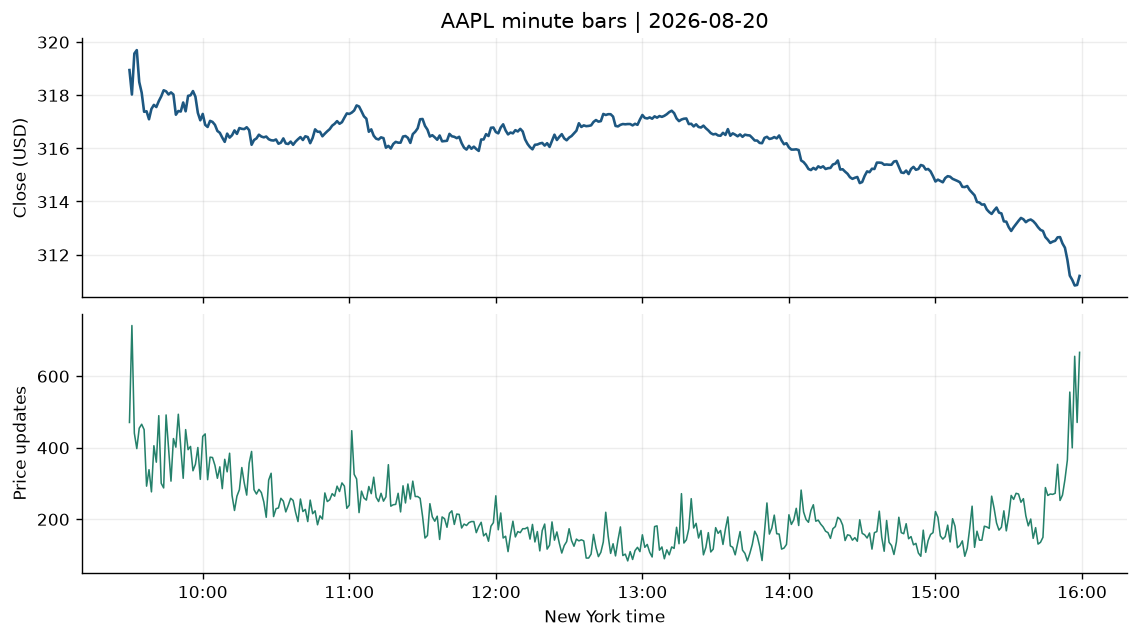

In [3]:
pred = pd.read_csv(results / "predictions.csv")
pred["target_time"] = pd.to_datetime(pred["target_time"], utc=True).dt.tz_convert(ny)
day = pred["session"].iloc[0]  # Change to any date in the test split.

bars = pd.read_csv(data)
bars["datetime"] = pd.to_datetime(bars["datetime"], utc=True).dt.tz_convert(ny)
bars = bars.set_index("datetime").sort_index().between_time("09:30", "15:59")
session = bars.loc[day:day]
fig, (price_ax, activity_ax) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, layout="constrained")
price_ax.plot(session.index, session["close"], color="#1d5781")
price_ax.set(title=f"AAPL minute bars | {day}", ylabel="Close (USD)")
activity_ax.plot(session.index, session["volume"], color="#25816b", linewidth=.9)
activity_ax.set(ylabel="Price updates", xlabel="New York time")
activity_ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=ny))
plt.show()

## 看報酬誤差與價格誤差

價格曲線容易因為沿用當前價位而顯得貼近。下圖用同一個訊號時點的股價當基準，把實際變動與預測變動放在一起，再用整個測試期的美元 MAE 比對。

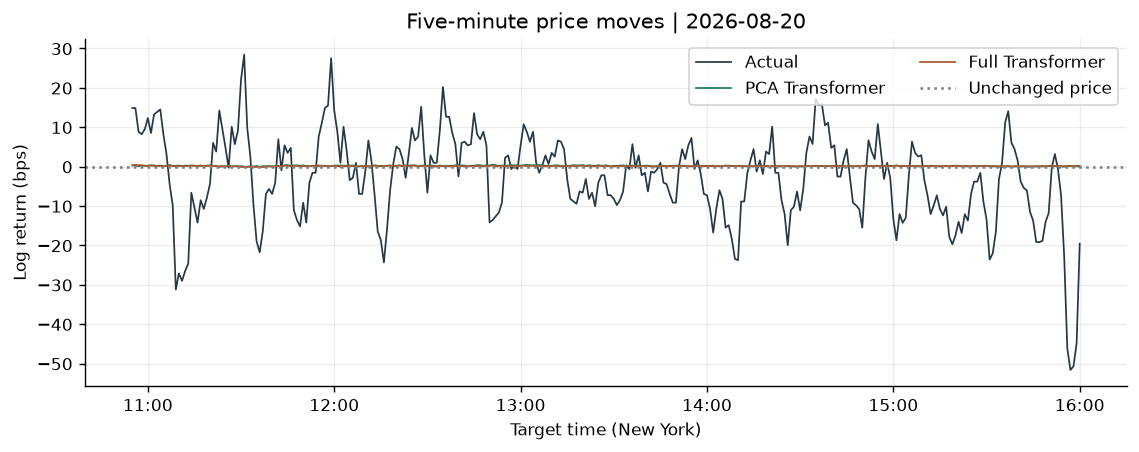

In [4]:
view = pred.loc[pred["session"].eq(day)]
if view.empty:
    raise ValueError("Choose a date in the test split.")
fig, ax = plt.subplots(layout="constrained")
for column, label, color in [("actual_price", "Actual", "#263745"),
                             ("pca_transformer_price", "PCA Transformer", "#207b68"),
                             ("full_transformer_price", "Full Transformer", "#ad5427")]:
    change = 1e4 * np.log(view[column] / view["price"])
    ax.plot(view["target_time"], change, label=label, color=color, linewidth=1)
ax.axhline(0, linestyle=":", color="gray", label="Unchanged price")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=ny))
ax.set(title=f"Five-minute price moves | {day}", ylabel="Log return (bps)", xlabel="Target time (New York)")
ax.legend(loc="upper right", ncols=2)
plt.show()

                  price_mae_usd  price_rmse_usd  return_mae_bps
model                                                          
unchanged_price        0.254999        0.364103        7.864574
historical_mean        0.254972        0.364019        7.863795
full_transformer       0.254855        0.363901        7.860209
pca_transformer        0.254992        0.364081        7.864530
PCA minus full MAE, paired 95% interval: [-0.000023, 0.000276] USD


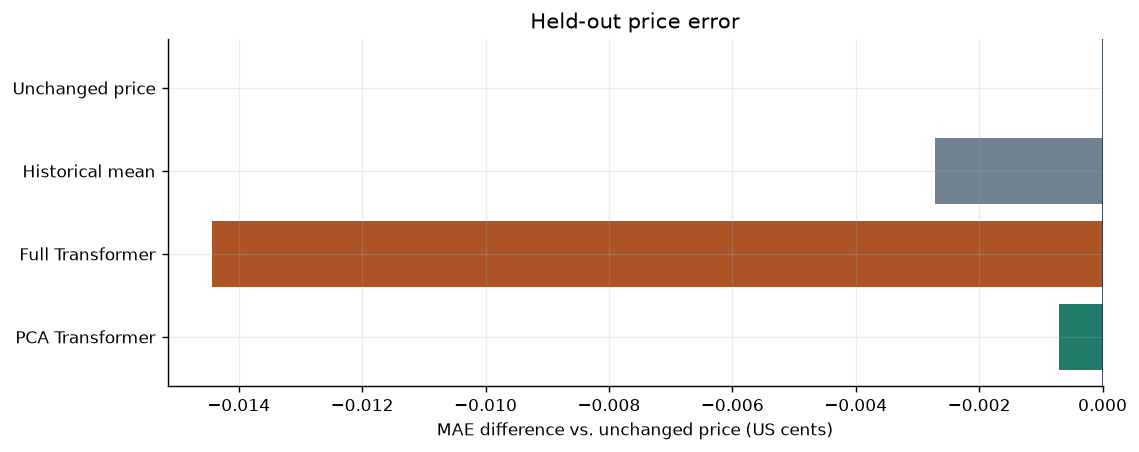

In [5]:
metrics = pd.read_csv(results / "metrics.csv")
model_names = {"unchanged_price": "Unchanged price", "historical_mean": "Historical mean",
               "full_transformer": "Full Transformer", "pca_transformer": "PCA Transformer"}
base = metrics.query("round_trip_bps == 0").set_index("model")
base = base.loc[list(model_names)]
print(base[["price_mae_usd", "price_rmse_usd", "return_mae_bps"]].round(6).to_string())
low, high = run["pca_minus_full_mae_usd_95ci"]
print(f"PCA minus full MAE, paired 95% interval: [{low:.6f}, {high:.6f}] USD")

delta = (base["price_mae_usd"] - base.loc["unchanged_price", "price_mae_usd"]) * 100
fig, ax = plt.subplots(layout="constrained")
positions = np.arange(len(delta))
ax.barh(positions, delta, color=["#718190", "#718190", "#ad5427", "#207b68"])
ax.set(yticks=positions, yticklabels=[model_names[key] for key in delta.index],
       xlabel="MAE difference vs. unchanged price (US cents)", title="Held-out price error")
ax.axvline(0, color="#263745", linewidth=1)
ax.invert_yaxis()
plt.show()

## 交易成本與回測

每五分鐘檢查訊號，預測變動超過來回成本門檻才模擬交易。成本變動也會改變交易筆數。零成本下的報酬應連同其他情境的交易筆數閱讀。

round_trip_bps      0   2   5   10
model                             
full_transformer  1527   0   0   0
historical_mean   1527   0   0   0
pca_transformer   1527   0   0   0
unchanged_price      0   0   0   0


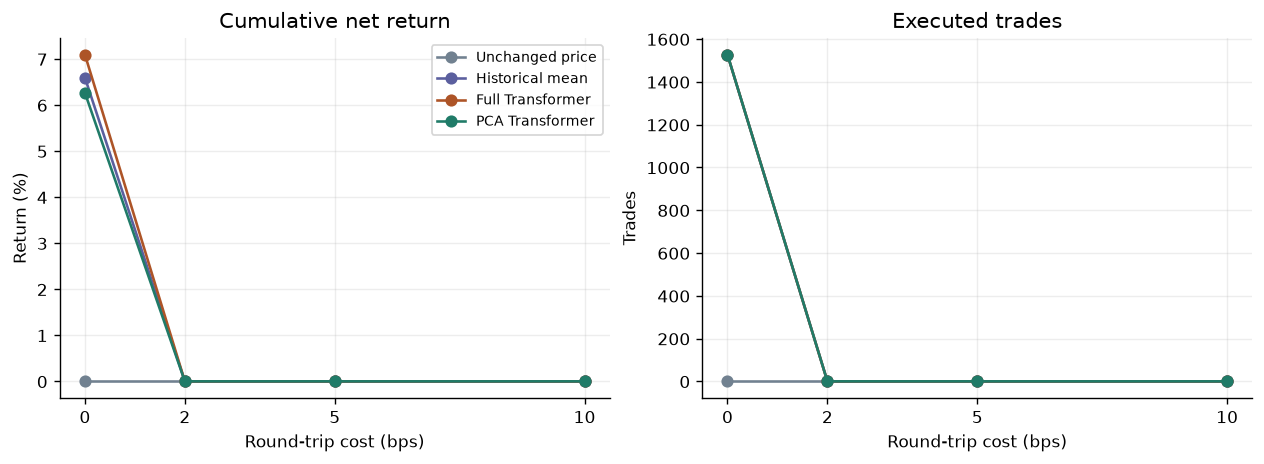

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for key, color in zip(model_names, ["#718190", "#5b5f9e", "#ad5427", "#207b68"]):
    scenario = metrics.loc[metrics["model"].eq(key)].sort_values("round_trip_bps")
    for ax, values in zip(axes, [scenario["net_cumulative"] * 100, scenario["trades"]]):
        ax.plot(scenario["round_trip_bps"], values, marker="o", color=color, label=model_names[key])
        ax.set(xlabel="Round-trip cost (bps)", xticks=[0, 2, 5, 10])
axes[0].set(title="Cumulative net return", ylabel="Return (%)")
axes[1].set(title="Executed trades", ylabel="Trades")
axes[0].legend(fontsize=8)
plt.show()
print(metrics.pivot(index="model", columns="round_trip_bps", values="trades").to_string())